<a href="https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Fase3_EDA_Molecular_Auto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 3. Análisis exploratorio y exploración molecular
Proyecto: Cuando la química compromete la cura

En este notebook se descarga DILIst desde la FDA y uso una copia pública del mismo Excel en GitHub si la FDA bloquea la petición de Colab. Además voy a comparar las etiquetas DILI con peso molecular, LogP, donadores H, aceptores H y TPSA para así calcular la regla de Lipinski. También obtendré los ATC (para saber las familias farmacológicas a los que pertenece cada fármaco y poder agruparlos, llegaré hasta el segundo nivel).

Lipinski incluye cuatro criterios (peso ≤500 Da, LogP ≤5, HBD ≤5 y HBA ≤10). TPSA es un descriptor complementario. La consulta de estructuras en PubChem puede tardar varios minutos.

In [1]:
# Instalo librerías para química, gráficos y consulta de estructuras. Voy a instalar una librería mía que es de interpretabilidad.
!pip -q install rdkit pubchempy requests openpyxl git+https://github.com/PARODBE/comptox_analysis.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Importo herramientas y descargo DILIst desde la FDA.
import re, time, unicodedata, requests, pubchempy as pcp
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from io import BytesIO
from IPython.display import display
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, Draw
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from comptox_analysis.highlighting.highlighting_atoms import highlighter

from rdkit import RDLogger
RDLogger.DisableLog('rdApp.warning')

# Pruebo primero la FDA; si Colab recibe su página antiabuso, uso una copia pública del mismo Excel.
fuentes = [
    'https://www.fda.gov/media/160597/download',
    'https://raw.githubusercontent.com/tlee23-ic/GNN_DILI/main/DILIst%20%282020%29.xlsx'
]
original = None
errores_descarga = []
for fuente in fuentes:
    try:
        respuesta = requests.get(fuente, headers={'User-Agent':'Mozilla/5.0'}, timeout=60)
        respuesta.raise_for_status()
        # Un archivo xlsx empieza por PK; así no intento leer la página de bloqueo.
        if not respuesta.content.startswith(b'PK'):
            raise ValueError('La respuesta no parece ser un archivo Excel.')
        original = pd.read_excel(BytesIO(respuesta.content))
        print('Archivo de DILIst descargado correctamente.')
        break
    except Exception as error:
        errores_descarga.append(str(error))
        print('No se pudo usar esta fuente; se prueba la siguiente.')
if original is None:
    raise RuntimeError('Fallaron ambas fuentes de DILIst: ' + ' | '.join(errores_descarga))
original.columns = original.columns.astype(str).str.strip()

# Preparo una tabla mínima y guardo el CSV automáticamente.
limpiar = lambda x: re.sub(r'[^a-z0-9]', '', str(x).lower())
cols = {limpiar(c): c for c in original.columns}
id_col = cols.get('dilistid')
nombre_col = cols.get('compoundname') or cols.get('drugname')
clase_col = cols.get('dilistclassification') or cols.get('classification')
if not all([id_col, nombre_col, clase_col]):
    raise ValueError('No se encontraron las columnas principales: ' + str(list(original.columns)))
df = original[[id_col, nombre_col, clase_col]].copy()
df.columns = ['DILIST_ID', 'CompoundName', 'DILIst_Classification']
df['DILIST_ID'] = pd.to_numeric(df['DILIST_ID'], errors='coerce')
df['DILIst_Classification'] = pd.to_numeric(df['DILIst_Classification'], errors='coerce')
df['CompoundName'] = df['CompoundName'].astype('string').str.strip()
df.to_csv('dilist_trabajo.csv', index=False)
print('DILIst:', df.shape)
display(df.head())

Archivo de DILIst descargado correctamente.
DILIst: (1279, 3)


,DILIST_ID,CompoundName,DILIst_Classification
0,1,mercaptopurine,1
1,2,acetaminophen,1
2,3,azathioprine,1
3,4,chlorpheniramine,0
4,5,clofibrate,1


,n,porcentaje
DILIst_Classification,,
Negativa,511,40.0
Positiva,768,60.0


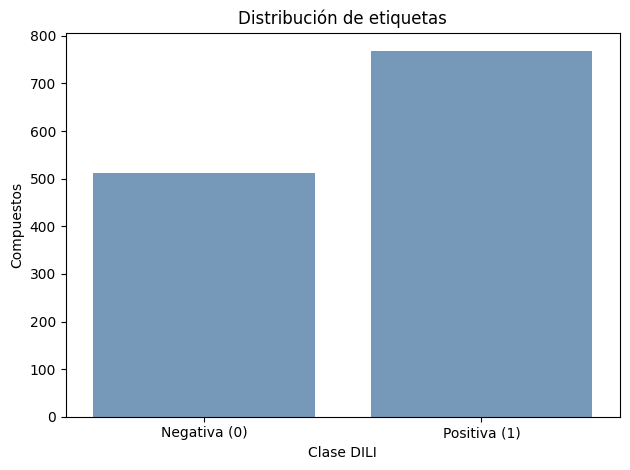

In [3]:
# Distribución de las dos clases DILI.
clases = df['DILIst_Classification'].value_counts().sort_index().to_frame('n')
clases['porcentaje'] = (100 * clases['n'] / len(df)).round(1)
display(clases.rename(index={0:'Negativa', 1:'Positiva'}))
sns.countplot(data=df, x='DILIst_Classification', color='#6B9AC4')
plt.xticks([0,1], ['Negativa (0)','Positiva (1)'])
plt.xlabel('Clase DILI'); plt.ylabel('Compuestos'); plt.title('Distribución de etiquetas')
plt.tight_layout(); plt.show()

## Estructuras químicas de PubChem
Se consulta cada nombre distinto automáticamente. Se conserva una estructura solo cuando la búsqueda devuelve una coincidencia inequívoca. Los fallos y nombres ambiguos quedan registrados.

In [17]:
# Para probar más rápido se puede cambiar None por 20; para el análisis completo se deja None.
LIMITE = None
compuestos = df.drop_duplicates('CompoundName')
if LIMITE is not None:
    compuestos = compuestos.head(LIMITE)

# Consulto PubChem con reintentos ante errores temporales.
def buscar(nombre):
    for intento in range(4):
        try:
            return pcp.get_compounds(nombre, 'name')
        except Exception as error:
            codigo = getattr(error, 'code', None)
            temporal = codigo in [429,500,502,503,504] or 'timeout' in str(error).lower()
            if not temporal or intento == 3:
                raise
            time.sleep(2 ** (intento + 1))

resultados = []
for numero, (_, fila) in enumerate(compuestos.iterrows(), start=1):
    nombre = str(fila['CompoundName']).strip()
    try:
        encontrados = buscar(nombre)
        if len(encontrados) == 1 and encontrados[0].isomeric_smiles:
            dato = [encontrados[0].cid, encontrados[0].isomeric_smiles, 'resuelto']
        elif len(encontrados) > 1:
            dato = [None, None, 'ambiguo']
        else:
            dato = [None, None, 'no_encontrado']
    except Exception as error:
        dato = [None, None, 'error_consulta']
        print('Falló:', nombre, str(error)[:70])
    resultados.append([fila['DILIST_ID'], nombre, fila['DILIst_Classification'], *dato])
    if numero % 25 == 0:
        pd.DataFrame(resultados).to_csv('estructuras_parcial.csv', index=False)
        print('Consultados', numero, 'de', len(compuestos))
    time.sleep(0.2)

estructuras = pd.DataFrame(resultados, columns=[
    'DILIST_ID','CompoundName','DILIst_Classification','CID','SMILES','estado_busqueda'])
estructuras.to_csv('estructuras_pubchem.csv', index=False)
estructuras[estructuras['estado_busqueda'] != 'resuelto'].to_csv(
    'estructuras_pendientes_revision.csv', index=False)
display(estructuras['estado_busqueda'].value_counts().to_frame('n'))

Consultados 25 de 1279
Consultados 50 de 1279
Consultados 75 de 1279
Consultados 100 de 1279
Consultados 125 de 1279
Consultados 150 de 1279
Consultados 175 de 1279
Consultados 200 de 1279
Consultados 225 de 1279
Consultados 250 de 1279
Consultados 275 de 1279
Consultados 300 de 1279
Consultados 325 de 1279
Consultados 350 de 1279
Consultados 375 de 1279
Consultados 400 de 1279
Consultados 425 de 1279
Consultados 450 de 1279
Consultados 475 de 1279
Consultados 500 de 1279
Consultados 525 de 1279
Consultados 550 de 1279
Consultados 575 de 1279
Consultados 600 de 1279
Consultados 625 de 1279
Consultados 650 de 1279
Consultados 675 de 1279
Consultados 700 de 1279
Consultados 725 de 1279
Consultados 750 de 1279
Consultados 775 de 1279
Consultados 800 de 1279
Consultados 825 de 1279
Consultados 850 de 1279
Consultados 875 de 1279
Consultados 900 de 1279
Consultados 925 de 1279
Consultados 950 de 1279
Consultados 975 de 1279
Consultados 1000 de 1279
Consultados 1025 de 1279
Consultados 1050 

,n
estado_busqueda,
resuelto,1179
no_encontrado,91
ambiguo,9


Hay 91 fármacos que no hemos encontrado en pubchem, por lo que nuestro dataset final que vamos a trabajar es 1179 fármacos

,DILIst_Classification,compuestos,estructuras,cobertura_pct
0,0,511,449,87.9
1,1,768,730,95.1


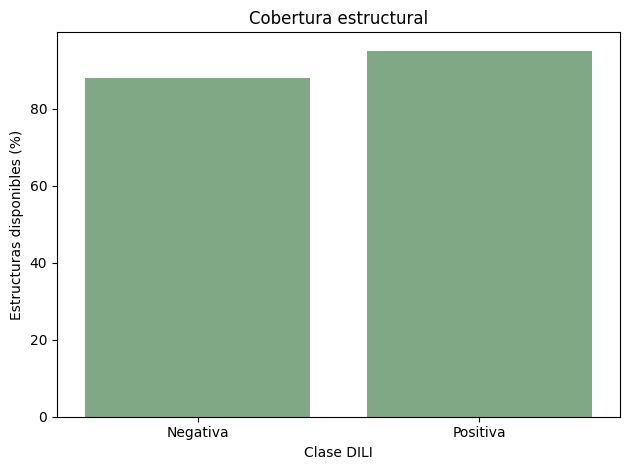

In [18]:
# Calculo la cobertura de estructuras según la clase DILI.
cobertura = df[['DILIST_ID','DILIst_Classification']].merge(
    estructuras[['DILIST_ID','estado_busqueda']], on='DILIST_ID', how='left')
cobertura['disponible'] = cobertura['estado_busqueda'].eq('resuelto')
resumen_cobertura = cobertura.groupby('DILIst_Classification').agg(
    compuestos=('DILIST_ID','nunique'), estructuras=('disponible','sum'),
    cobertura_pct=('disponible',lambda x:round(100*x.mean(),1))).reset_index()
display(resumen_cobertura)
sns.barplot(data=resumen_cobertura, x='DILIst_Classification', y='cobertura_pct', color='#7BAE7F')
plt.xticks([0,1],['Negativa','Positiva']); plt.ylabel('Estructuras disponibles (%)')
plt.xlabel('Clase DILI'); plt.title('Cobertura estructural')
plt.tight_layout(); plt.show()

In [19]:
# Calculo descriptores y criterios de Lipinski para cada estructura válida.
def propiedades(fila):
    mol = Chem.MolFromSmiles(fila['SMILES'])
    if mol is None:
        return None
    peso = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    hbd, hba = Lipinski.NumHDonors(mol), Lipinski.NumHAcceptors(mol)
    violaciones = sum([peso > 500, logp > 5, hbd > 5, hba > 10])
    return {'DILIST_ID':fila['DILIST_ID'],'CompoundName':fila['CompoundName'],
        'DILIst_Classification':fila['DILIst_Classification'],'CID':fila['CID'],
        'SMILES':fila['SMILES'],'Peso_molecular':peso,'LogP_RDKit':logp,
        'Donadores_H':hbd,'Aceptores_H':hba,'TPSA':rdMolDescriptors.CalcTPSA(mol),
        'Violaciones_Lipinski':violaciones,'Cumple_4_criterios':violaciones == 0,
        'Cero_o_una_violacion':violaciones <= 1}

descriptores = pd.DataFrame([propiedades(f) for _,f in estructuras.dropna(subset=['SMILES']).iterrows()])
descriptores = descriptores.dropna(subset=['Peso_molecular'])
descriptores.to_csv('descriptores_rdkit_lipinski.csv', index=False)
display(descriptores.head())

# Cuento cumplimiento de Lipinski por clase.
lipinski_por_clase = descriptores.groupby('DILIst_Classification').agg(
    n=('DILIST_ID','nunique'), cumplen=('Cumple_4_criterios','sum'),
    porcentaje_cumple=('Cumple_4_criterios',lambda x:round(100*x.mean(),1)),
    cero_o_una=('Cero_o_una_violacion','sum'),
    porcentaje_cero_una=('Cero_o_una_violacion',lambda x:round(100*x.mean(),1)))
display(lipinski_por_clase)

,DILIST_ID,CompoundName,DILIst_Classification,CID,SMILES,Peso_molecular,LogP_RDKit,Donadores_H,Aceptores_H,TPSA,Violaciones_Lipinski,Cumple_4_criterios,Cero_o_una_violacion
0,1,mercaptopurine,1,667490.0,C1=NC2=C(N1)C(=S)N=CN2,152.182,1.01549,2,3,57.36,0,True,True
1,2,acetaminophen,1,1983.0,CC(=O)NC1=CC=C(C=C1)O,151.165,1.35060,2,2,49.33,0,True,True
2,3,azathioprine,1,2265.0,CN1C=NC(=C1SC2=NC=NC3=C2NC=N3)[N+](=O)[O-],277.269,1.14580,1,7,115.42,0,True,True
3,4,chlorpheniramine,0,2725.0,CN(C)CCC(C1=CC=C(C=C1)Cl)C2=CC=CC=N2,274.795,3.81860,0,2,16.13,0,True,True
4,5,clofibrate,1,2796.0,CCOC(=O)C(C)(C)OC1=CC=C(C=C1)Cl,242.702,3.06050,0,3,35.53,0,True,True


,n,cumplen,porcentaje_cumple,cero_o_una,porcentaje_cero_una
DILIst_Classification,,,,,
0,449,320,71.3,380,84.6
1,730,578,79.2,656,89.9


No hay practicamente diferente entre la clase positiva y negativa entre los compuestos si cumplen o no la regla de lipinski, probablemente porque partimos que todos son practicamente drug-like.

,count,mean,std,min,25%,50%,75%,max
Peso_molecular,1179.0,420.96,470.06,18.02,259.35,334.40,432.53,7053.95
LogP_RDKit,1179.0,1.77,3.84,-49.12,0.68,2.37,3.72,9.91
Donadores_H,1179.0,2.96,7.08,0.00,1.00,2.00,3.00,100.00
Aceptores_H,1179.0,5.80,7.19,0.00,3.00,4.00,6.00,99.00
TPSA,1179.0,112.89,203.86,0.00,46.25,75.01,114.22,2912.95


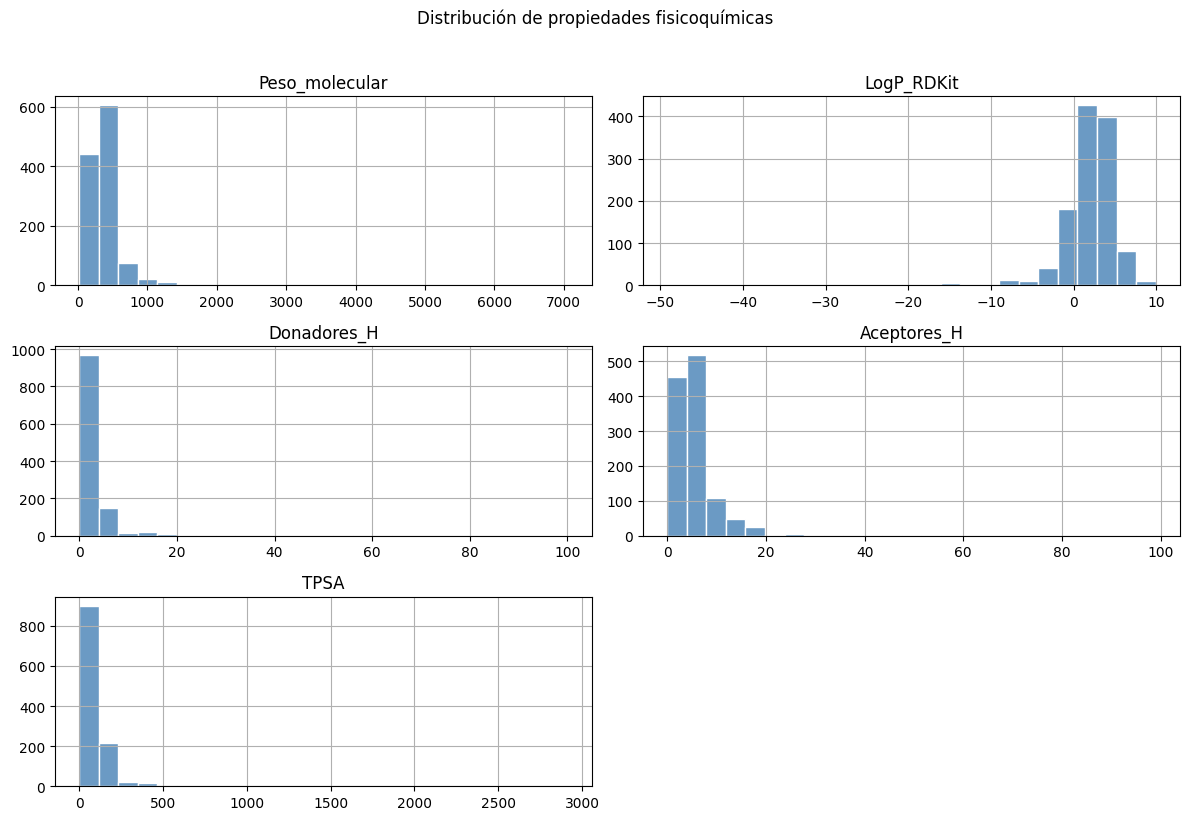

In [20]:
# Análisis univariado de las cinco propiedades seleccionadas.
variables = ['Peso_molecular','LogP_RDKit','Donadores_H','Aceptores_H','TPSA']
display(descriptores[variables].describe().T.round(2))
descriptores[variables].hist(bins=25, figsize=(12,8), color='#6B9AC4', edgecolor='white')
plt.suptitle('Distribución de propiedades fisicoquímicas', y=1.02)
plt.tight_layout(); plt.show()

DILIst_Classification,0,1
Peso_molecular,335.47,333.81
LogP_RDKit,1.85,2.64
Donadores_H,2.00,2.00
Aceptores_H,4.00,4.00
TPSA,75.27,74.67


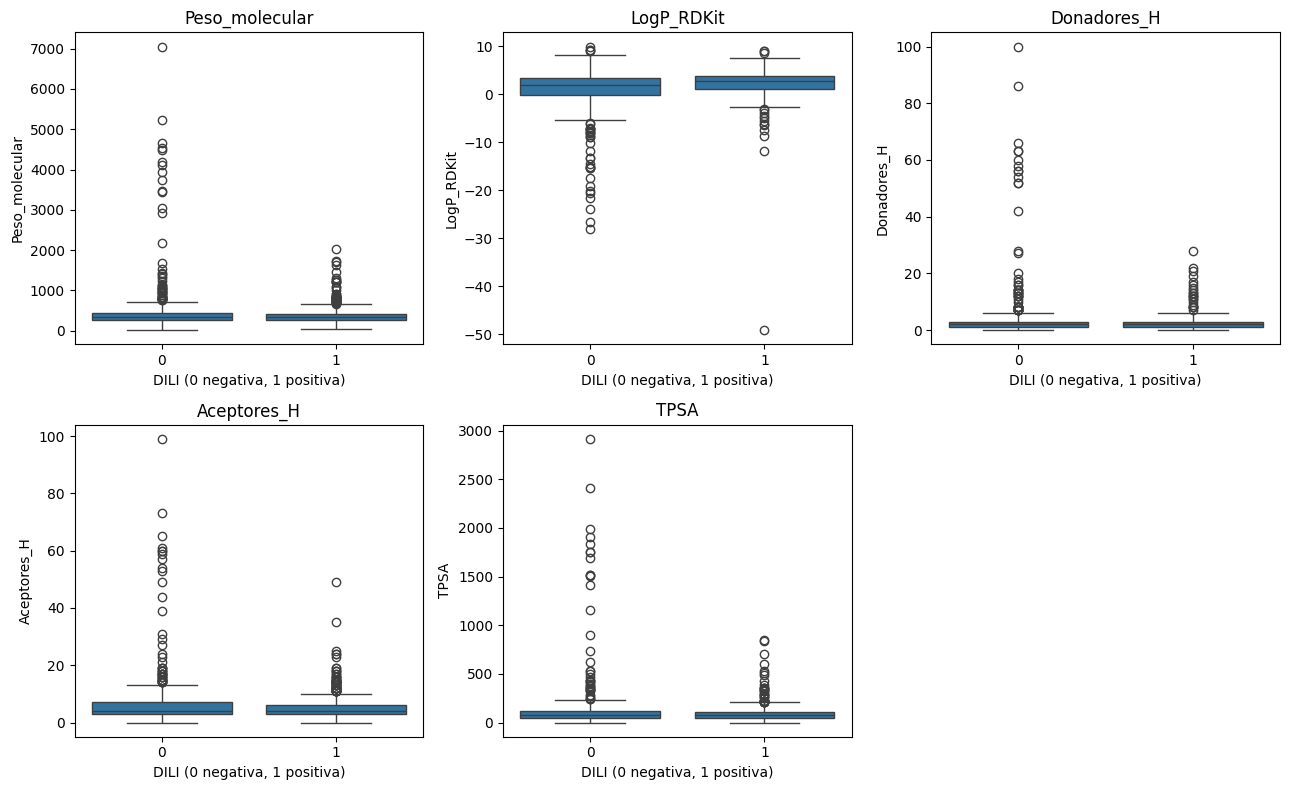

Las diferencias son descriptivas y solo incluyen compuestos con estructura resuelta.


In [21]:
# Análisis bivariado: medianas y diagramas de caja por etiqueta DILI.
display(descriptores.groupby('DILIst_Classification')[variables].median().T.round(2))
fig, axes = plt.subplots(2,3,figsize=(13,8))
for ax, variable in zip(axes.flat, variables):
    sns.boxplot(data=descriptores, x='DILIst_Classification', y=variable, ax=ax)
    ax.set_xlabel('DILI (0 negativa, 1 positiva)')
    ax.set_title(variable)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()
print('Las diferencias son descriptivas y solo incluyen compuestos con estructura resuelta.')

Si que es cierto que el LogP es mayor en compuestos hepatotóxicos lo que puede ser clave ya que permitiría atravesar barreras corporales y por tanto incrementar la toxicidad, ahí pueden estar las diferencias

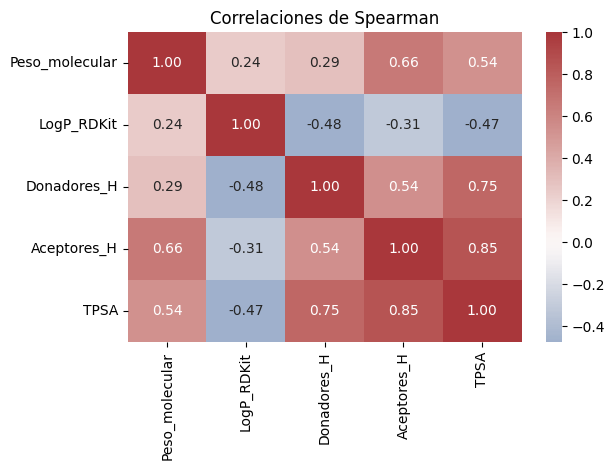

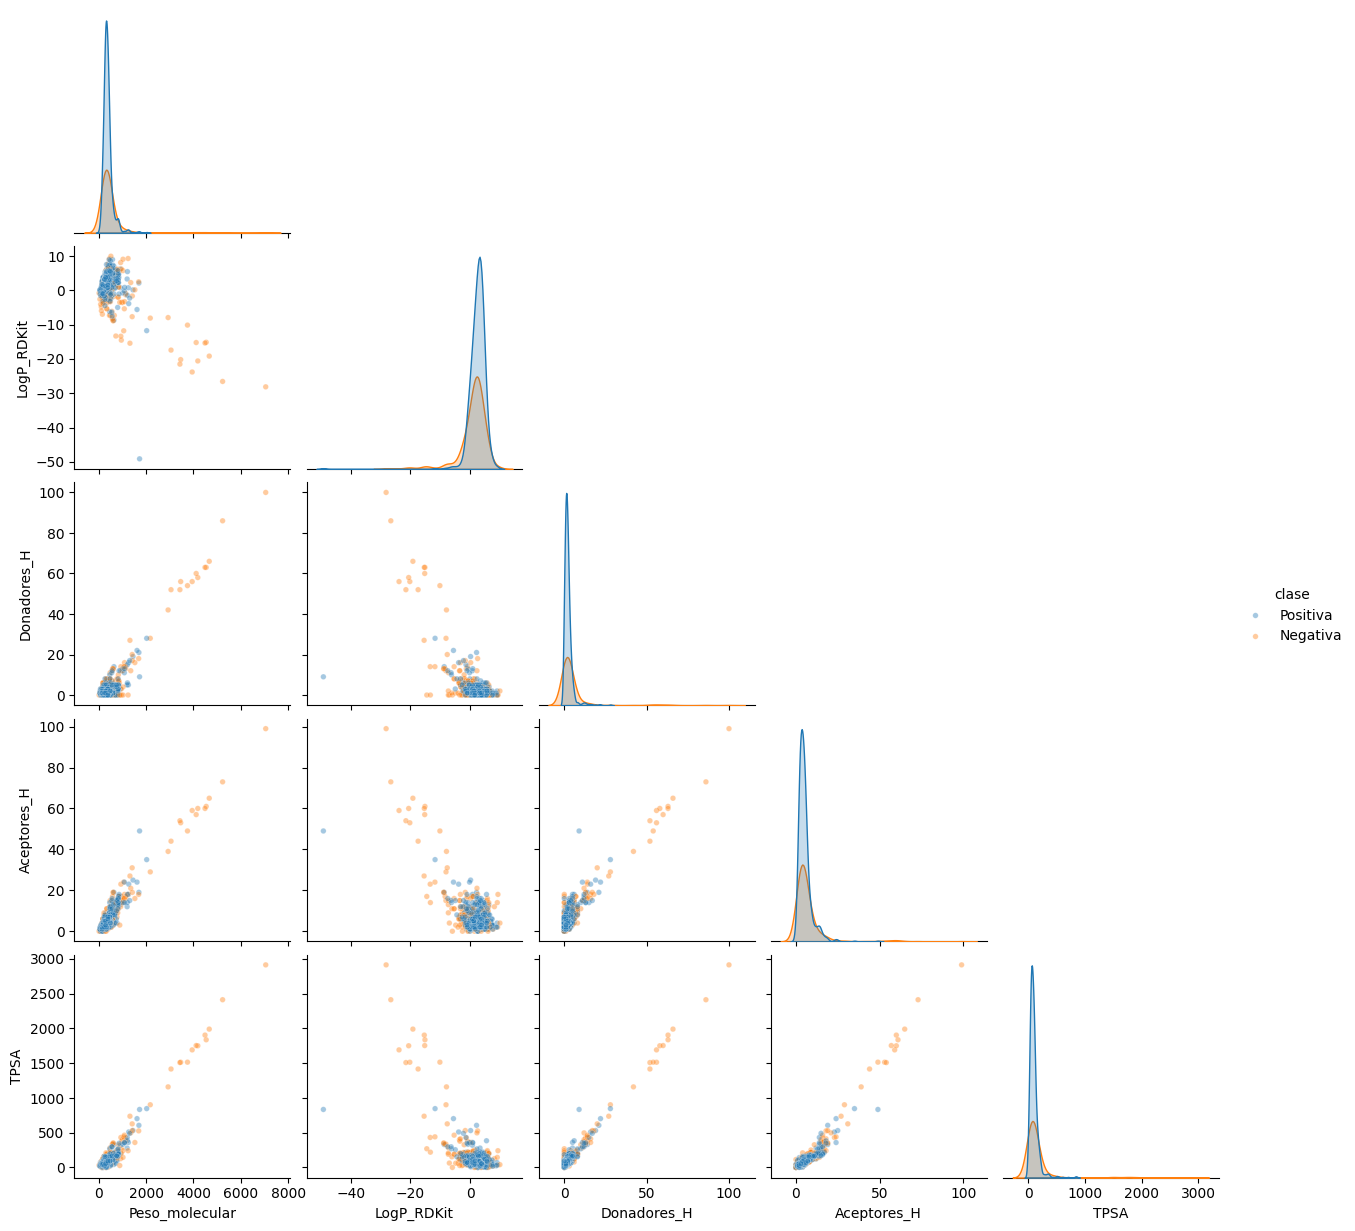

In [22]:
# Análisis multivariado de las cinco propiedades.
corr = descriptores[variables].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='vlag', center=0, fmt='.2f')
plt.title('Correlaciones de Spearman'); plt.tight_layout(); plt.show()
pares = descriptores[variables + ['DILIst_Classification']].copy()
pares['clase'] = pares['DILIst_Classification'].map({0:'Negativa',1:'Positiva'})
sns.pairplot(pares, vars=variables, hue='clase', corner=True,
             plot_kws={'alpha':0.4,'s':16})
plt.show()

,bit_morgan,n_negativos,n_positivos,n_total,prevalencia_negativa_pct,prevalencia_positiva_pct
0,0,447,707,1154,99.554566,96.849315
2,2,388,652,1040,86.414254,89.315068
4,4,346,609,955,77.060134,83.424658
2017,2017,316,567,883,70.378619,77.671233
2040,2040,295,509,804,65.701559,69.726027
428,428,285,464,749,63.474388,63.561644
792,792,265,369,634,59.020045,50.547945
1085,1085,228,387,615,50.779510,53.013699
1556,1556,236,365,601,52.561247,50.000000
1,1,183,364,547,40.757238,49.863014


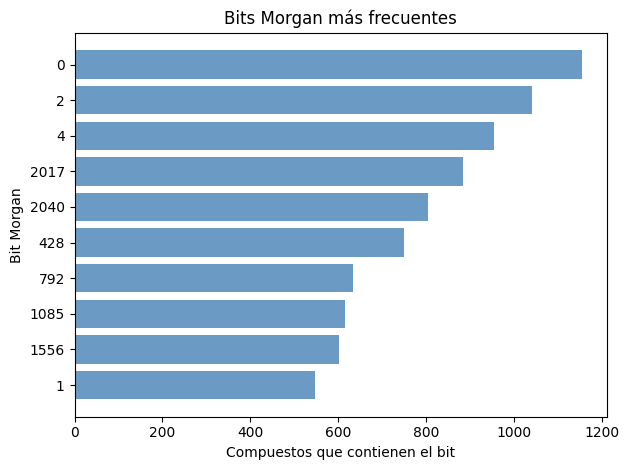

In [23]:
# Construyos fingerprints Morgan Feature con radio 2 y 2048 bits.
moleculas = [Chem.MolFromSmiles(s) for s in descriptores['SMILES']]
fingerprints, informacion_bits = [], []
for mol in moleculas:
    bit_info = {}
    fingerprints.append(GetMorganFingerprintAsBitVect(
        mol, radius=2, nBits=2048, useFeatures=True, bitInfo=bit_info))
    informacion_bits.append(bit_info)

matriz_bits = np.zeros((len(fingerprints),2048), dtype=np.uint8)
for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, matriz_bits[i])
np.savez_compressed('fingerprints_morgan.npz', bits=matriz_bits,
    DILIST_ID=descriptores['DILIST_ID'].to_numpy(),
    clase=descriptores['DILIst_Classification'].to_numpy())

# Resumo frecuencia y porcentajes por clase.
etiquetas = descriptores['DILIst_Classification'].to_numpy()
neg, pos = etiquetas==0, etiquetas==1
tabla_bits = pd.DataFrame({'bit_morgan':range(2048),
    'n_negativos':matriz_bits[neg].sum(axis=0),
    'n_positivos':matriz_bits[pos].sum(axis=0)})
tabla_bits['n_total'] = tabla_bits['n_negativos'] + tabla_bits['n_positivos']
tabla_bits['prevalencia_negativa_pct'] = 100*tabla_bits['n_negativos']/max(neg.sum(),1)
tabla_bits['prevalencia_positiva_pct'] = 100*tabla_bits['n_positivos']/max(pos.sum(),1)
tabla_bits.to_csv('prevalencia_bits_morgan.csv', index=False)
bits_frecuentes = tabla_bits[tabla_bits['n_total']>=5].sort_values('n_total',ascending=False)
if bits_frecuentes.empty:
    bits_frecuentes = tabla_bits[tabla_bits['n_total']>0].sort_values('n_total',ascending=False)
display(bits_frecuentes.head(12))
graf = bits_frecuentes.head(10).sort_values('n_total')
plt.barh(graf['bit_morgan'].astype(str),graf['n_total'],color='#6B9AC4')
plt.xlabel('Compuestos que contienen el bit'); plt.ylabel('Bit Morgan')
plt.title('Bits Morgan más frecuentes'); plt.tight_layout(); plt.show()

Los 3 primeros bits más recurrentes son el 0,2, y 4 vamos a verlo en un ejemplo

## Compuesto, descomposición y tres bits más frecuentes en acetaminophen
Se muestra una sola estructura de acetaminophen con sus tres bits Morgan más frecuentes en el conjunto resaltados a la vez. También se presenta su descomposición.

Compuesto: acetaminophen
Tres bits más frecuentes presentes: [0, 2, 4]


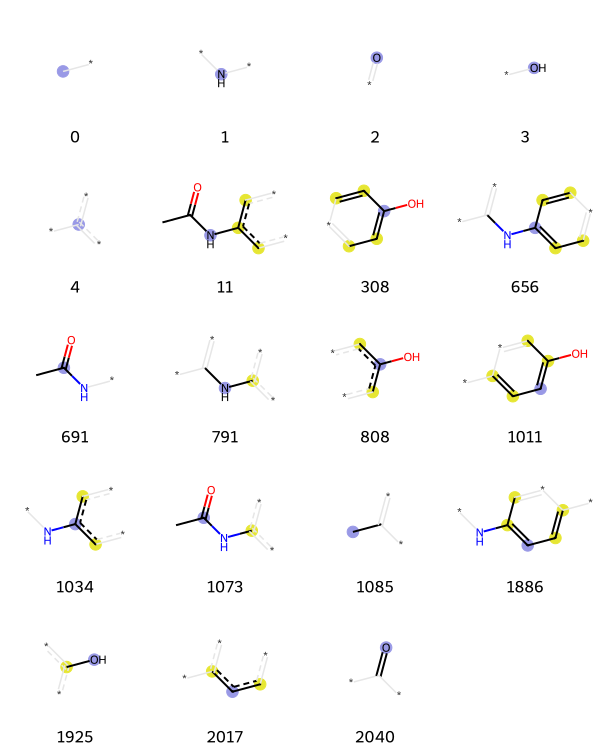

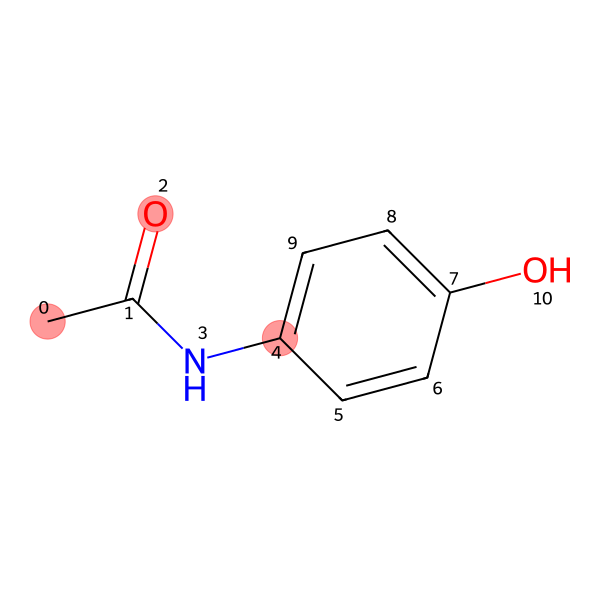

In [24]:
# Selecciono acetaminophen y calculo sus bits Morgan.
fila = descriptores[descriptores['CompoundName'].astype(str).str.casefold().str.strip() == 'acetaminophen']
if fila.empty:
    print('No hay estructura resuelta para acetaminophen.')
else:
    smiles = fila.iloc[0]['SMILES']
    mol = Chem.MolFromSmiles(smiles)
    bit_info = {}
    fp = GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048,
        useFeatures=True, bitInfo=bit_info)

    # De los bits presentes en acetaminophen, tomos los tres más frecuentes en DILIst.
    bits_presentes = set(fp.GetOnBits())
    bits_top_acetaminophen = (bits_frecuentes[bits_frecuentes['bit_morgan'].isin(bits_presentes)]
        .sort_values('n_total', ascending=False).head(3)['bit_morgan'].astype(int).tolist())

    print('Compuesto: acetaminophen')
    print('Tres bits más frecuentes presentes:', bits_top_acetaminophen)

    # La librería recibe el SMILES, no el objeto Mol de RDKit
    visor = highlighter([smiles])

    # Muestro la descomposición
    display(visor.fragmentation(n=26, number=0)[0])

    # Resalto los tres bits juntos en una sola estructura
    display(visor.highlighting(
        type='morgan',
        fingerprint_numbers=[bits_top_acetaminophen]
    ))


## ATC hasta nivel 2
El mapa ATC se lee desde el fichero público utilizado por PyHealth, sin instalar PyHealth. Para asignar los grupos se buscan coincidencias por nombre normalizado o por SMILES canónico.

La clasificación ATC de la OMS agrupa los medicamentos según el órgano o sistema sobre el que actúan y sus características terapéuticas, farmacológicas y químicas. Tiene cinco niveles: el primero indica el grupo anatómico o farmacológico principal; el segundo, un subgrupo terapéutico o farmacológico; los niveles tercero y cuarto lo detallan más; y el quinto identifica la sustancia química. www.who.int

En este análisis se conserva hasta el segundo nivel, formado por los tres primeros caracteres del código. Por ejemplo, J01CA01 corresponde a ampicilina: J es el grupo de antiinfecciosos sistémicos y J01 el subgrupo de antibacterianos sistémicos. Se utiliza J01 para comparar grupos amplios sin dividir los datos en categorías muy específicas.

Los porcentajes indican qué proporción de los compuestos de DILIst asignados a cada grupo tiene una etiqueta DILI positiva. Describen este conjunto de datos y no estiman el riesgo de hepatotoxicidad en pacientes.

[18:42:51] SMILES Parse Error: syntax error while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[18:42:51] SMILES Parse Error: check for mistakes around position 76:
[18:42:51] C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C
[18:42:51] ~~~~~~~~~~~~~~~~~~~~^
[18:42:51] SMILES Parse Error: extra open parentheses while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[18:42:51] SMILES Parse Error: check for mistakes around position 32:
[18:42:51] C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2
[18:42:51] ~~~~~~~~~~~~~~~~~~~~^
[18:42:51] SMILES Parse Error: extra open parentheses while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[18:42:51] SMILES Parse Error: check for mistakes around position 49:
[18:42:51] )\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=

Compuestos con grupo ATC: 1096


,ATC2,ATC2_nombre,n,positivos,porcentaje_positivo
54,M01,ANTIINFLAMMATORY AND ANTIRHEUMATIC PRODUCTS,42,40,95.2
55,M02,TOPICAL PRODUCTS FOR JOINT AND MUSCULAR PAIN,16,15,93.8
1,A02,DRUGS FOR ACID RELATED DISORDERS,15,14,93.3
51,L02,ENDOCRINE THERAPY ANTINEOPLASTIC AND IMMUNOMOD...,10,9,90.0
24,C09,AGENTS ACTING ON THE RENIN-ANGIOTENSIN SYSTEM,20,17,85.0
39,G03,SEX HORMONES AND MODULATORS OF THE GENITAL SYSTEM,21,17,81.0
64,N06,PSYCHOANALEPTICS,47,38,80.9
61,N03,ANTIEPILEPTICS,20,16,80.0
25,C10,LIPID MODIFYING AGENTS,19,15,78.9
47,J04,ANTIMYCOBACTERIALS,12,9,75.0


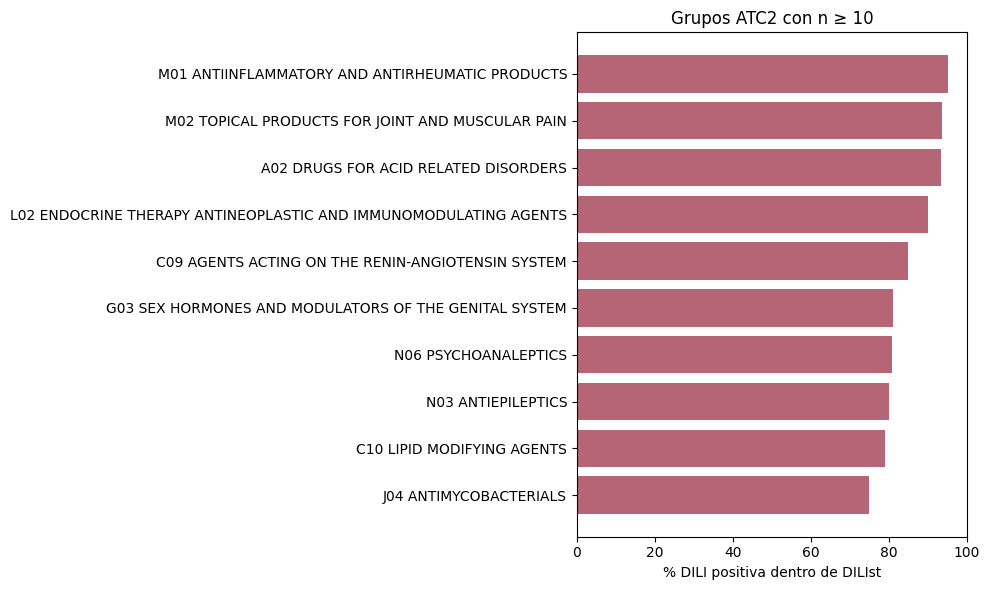

,ATC2,ATC2_nombre,n,peso_mediano,LogP_mediano,HBD_mediano,HBA_mediano,TPSA_mediana,cumple_lipinski_pct
0,A02,DRUGS FOR ACID RELATED DISORDERS,14,352.4,2.6,2.0,5.0,83.5,100.0
1,C09,AGENTS ACTING ON THE RENIN-ANGIOTENSIN SYSTEM,20,426.5,2.9,2.0,5.0,95.9,85.0
2,L02,ENDOCRINE THERAPY ANTINEOPLASTIC AND IMMUNOMOD...,10,296.4,3.1,1.0,3.0,72.2,70.0
3,M01,ANTIINFLAMMATORY AND ANTIRHEUMATIC PRODUCTS,42,294.9,3.1,1.0,3.0,62.3,97.6
4,M02,TOPICAL PRODUCTS FOR JOINT AND MUSCULAR PAIN,16,289.2,3.1,1.0,3.0,60.1,100.0


""


In [25]:
# Descargo el mapa de códigos ATC publicado junto a PyHealth.
atc = pd.read_csv('https://storage.googleapis.com/pyhealth/resource/ATC.csv')
atc.columns = atc.columns.astype(str).str.strip().str.lower()
if not {'code','name'}.issubset(atc.columns):
    raise ValueError('No se reconocen las columnas code y name de la tabla ATC.')

# Comparo nombres normalizados y, si hace falta, SMILES canónicos.
def nombre_simple(x):
    x = unicodedata.normalize('NFKD', str(x)).encode('ascii','ignore').decode('ascii')
    return re.sub(r'[^a-z0-9]','',x.lower())
def smiles_simple(x):
    if pd.isna(x): return None
    m = Chem.MolFromSmiles(str(x))
    return Chem.MolToSmiles(m, canonical=True, isomericSmiles=False) if m else None

atc['code'] = atc['code'].astype(str).str.upper().str.strip()
atc['nombre_simple'] = atc['name'].map(nombre_simple)
nombres_atc2 = {r['code']:r['name'] for _,r in atc.iterrows() if len(r['code'])==3}
por_nombre = {}
for _,r in atc.iterrows():
    if len(r['code'])>3 and r['nombre_simple']:
        por_nombre.setdefault(r['nombre_simple'],[]).append(r['code'])
por_smiles = {}
if 'smiles' in atc.columns:
    tmp = atc.dropna(subset=['smiles']).copy()
    tmp['smiles_simple'] = tmp['smiles'].map(smiles_simple)
    for _,r in tmp.dropna(subset=['smiles_simple']).iterrows():
        if len(r['code'])>3:
            por_smiles.setdefault(r['smiles_simple'],[]).append(r['code'])

# Asigno nivel 2 con nombre exacto o estructura exacta.
asignaciones = []
for _,r in df.drop_duplicates('DILIST_ID').iterrows():
    codigos = sorted(set(por_nombre.get(nombre_simple(r['CompoundName']),[])))
    metodo = 'nombre'
    if not codigos:
        estructura = estructuras[estructuras['DILIST_ID']==r['DILIST_ID']]
        clave = smiles_simple(estructura.iloc[0]['SMILES']) if len(estructura) else None
        codigos = sorted(set(por_smiles.get(clave,[]))) if clave else []
        metodo = 'SMILES'
    for cod in codigos:
        grupo = cod[:3]
        asignaciones.append({'DILIST_ID':r['DILIST_ID'],'CompoundName':r['CompoundName'],
            'DILIst_Classification':r['DILIst_Classification'],'ATC2':grupo,
            'ATC2_nombre':nombres_atc2.get(grupo,grupo),'metodo':metodo})
df_atc = pd.DataFrame(asignaciones).drop_duplicates(['DILIST_ID','ATC2'])
df_atc.to_csv('dilist_atc_coincidencias.csv',index=False)
print('Compuestos con grupo ATC:',df_atc['DILIST_ID'].nunique())

if len(df_atc):
    # Ordeno grupos por porcentaje de etiquetas positivas; muestro también su tamaño.
    resumen_atc = df_atc.groupby(['ATC2','ATC2_nombre']).agg(
        n=('DILIST_ID','nunique'), positivos=('DILIst_Classification','sum'),
        porcentaje_positivo=('DILIst_Classification',lambda x:100*x.mean())).reset_index()
    resumen_atc = resumen_atc[resumen_atc['n']>=10].sort_values('porcentaje_positivo',ascending=False)
    resumen_atc.to_csv('resumen_atc_nivel2.csv',index=False)
    display(resumen_atc.head(12).round(1))
    if len(resumen_atc):
        graf = resumen_atc.head(10).sort_values('porcentaje_positivo')
        plt.figure(figsize=(10,6))
        plt.barh(graf['ATC2']+' '+graf['ATC2_nombre'],graf['porcentaje_positivo'],color='#B56576')
        plt.xlabel('% DILI positiva dentro de DILIst'); plt.title('Grupos ATC2 con n ≥ 10')
        plt.tight_layout(); plt.show()

    # Comparo propiedades Lipinski y los bits frecuentes en los cinco grupos principales.
    cols = ['DILIST_ID','Peso_molecular','LogP_RDKit','Donadores_H','Aceptores_H','TPSA','Cumple_4_criterios']
    atc_mol = df_atc.merge(descriptores[cols].drop_duplicates('DILIST_ID'),on='DILIST_ID',how='inner')
    grupos = resumen_atc.head(5)['ATC2'].tolist()
    perfil = atc_mol[atc_mol['ATC2'].isin(grupos)].groupby(['ATC2','ATC2_nombre']).agg(
        n=('DILIST_ID','nunique'), peso_mediano=('Peso_molecular','median'),
        LogP_mediano=('LogP_RDKit','median'),HBD_mediano=('Donadores_H','median'),
        HBA_mediano=('Aceptores_H','median'),TPSA_mediana=('TPSA','median'),
        cumple_lipinski_pct=('Cumple_4_criterios',lambda x:100*x.mean())).reset_index()
    display(perfil.round(1))

    # Saco los cinco bits Morgan más frecuentes dentro de esos grupos.
    indice_id = {str(x):i for i,x in enumerate(descriptores['DILIST_ID'])}
    filas = []
    for grupo in grupos:
        ids = atc_mol.loc[atc_mol['ATC2']==grupo,'DILIST_ID'].unique()
        pos = [indice_id[str(x)] for x in ids if str(x) in indice_id]
        if pos:
            cuenta = matriz_bits[pos].sum(axis=0)
            for bit in np.argsort(-cuenta)[:5]:
                if cuenta[bit]:
                    filas.append({'ATC2':grupo,'bit_morgan':int(bit),'n_compuestos':int(cuenta[bit])})
    bits_por_atc = pd.DataFrame(filas)
    display(bits_por_atc)
    bits_por_atc.to_csv('bits_morgan_por_atc2.csv',index=False)
else:
    resumen_atc = pd.DataFrame()
    print('No hubo coincidencias exactas de nombres/estructuras en la tabla ATC.')

El grupo que menos cumple la regla de lipinski de los 5 grupos ATC hasta el segundo nivel con más fármacos, es el L02 que es el grupo de los antineoplásicos, es normal porque suelen ser moleculas muy grandes y pesadas.